# SAMI: a few extra checks

**Questions:** Why might galaxy size change the dispersion? How could mergers move a galaxy away from a simple mass relation? What happens if the stellar-mass scale changes? What do the residuals tell us?

Put this notebook beside `SAMI_Faber_Jackson.ipynb` in `notebooks/`. Run the main notebook first to create `../results/selected_galaxies.csv`, then restart this notebook's kernel and run from the top with **`notebooks/` as the working directory**. It loads that saved sample and repeats the same fit, so it does not depend on variables in another notebook. The saved outputs below use the supplied 446-galaxy sample.

There are three kinds of calculation here: **size and merger illustrations from the lectures**, a **hypothetical mass-scale sensitivity check using the actual sample**, and **residual checks on the actual sample**. The illustrations are not extra observations or recovered histories of the SAMI galaxies. This notebook does not change the main notebook, its selection or its result files.

## Where the methods come from

| Code operation | Supplied teaching example |
|---|---|
| Variables, lists, arithmetic including `**`, indexing, `print`, `len` | Tutorial 1; Spotted Python Week 2 |
| `pd.read_csv`, named columns, `pd.DataFrame` | Tutorial 2: Pandas and Markdown |
| `value_counts`, Boolean masks with `&` / `\|` | Tutorial 1 solutions; Tutorial 4 selections |
| `np.array`, `np.sum` | Spotted Python Week 2 solutions, cells 25 and 38 |
| `np.log` and array arithmetic | Tutorial 4 and Spotted Python Week 3 |
| `np.linspace` | Spotted Python Week 4, ellipticity grid example |
| `stats.linregress`, slope, intercept, standard errors, `rvalue` | Tutorial 4 solutions, linear-fitting example |
| `plt.subplots`, `plt.plot`, labels, title, legend, `tight_layout`, `show` | Tutorial plotting examples; Spotted Python Week 4 |

The scientific models and diagnostics combine these taught operations. The tutorials do not contain this exact investigation. No extra fitting library, clipping routine, simulation package or cosmology calculator is used. The assessment brief's permitted-assistance and acknowledgement requirements still apply to this study companion.


## Start with the same galaxies

`mstar` is already log10 stellar mass in solar units. Here `sigma` will mean log10 dispersion, while `sample['sigma_re']` remains the measured dispersion in km/s. The repeat check should give zero; stop if it does not. The main notebook is responsible for the measurement and morphology cuts, including its unresolved `bad_class == 0` assumption.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sample = pd.read_csv('../results/selected_galaxies.csv')
ids = sample['catid'].value_counts()
print('Galaxies:', len(sample))
print('Repeated IDs:', len(ids[ids > 1]))

mass = np.array(sample['mstar'])
sigma = np.log(np.array(sample['sigma_re'])) / np.log(10)
fit = stats.linregress(mass, sigma)
line = fit.slope * mass + fit.intercept

print('Slope:', fit.slope, '+/-', fit.stderr)
print('Intercept:', fit.intercept, '+/-', fit.intercept_stderr)


FileNotFoundError: [Errno 2] No such file or directory: '../results/selected_galaxies.csv'

## 1. Why galaxy size matters

The lecture's virial argument gives the scaling

$$\sigma^2\sim\frac{G M_{\rm dyn}}{R}.$$

For similar structure and velocity distributions, keeping the gravitating mass fixed gives

$$\frac{\sigma}{\sigma_0}=\left(\frac{R_0}{R}\right)^{1/2}.$$

This is a ratio calculation: the common mass and gravitational constant cancel. A radius ratio of 2 means twice the reference size. The corresponding dispersion ratio is $1/\sqrt{2}\simeq0.707$. The lecture's 4 kpc versus 8 kpc example gives twice the **mean square speed** in the smaller system, not twice the speed.

**What this checks:** can galaxies at the same gravitating mass have different dispersions just because their sizes differ? The model says yes. It does not establish that size causes the measured scatter in our stellar-mass relation. Stellar mass is not identical to total gravitating mass, and observed aperture dispersion is not automatically the global velocity scale in the virial theorem.

**Sources:** `PHYS3116_2026T3_lecture_05_Mon3_vibe_annotated-2.pdf`, PDF pp. 11 and 31; `PHYS3116_2026T3_lecture_02_Thu1-1.pdf`, virial-theorem section.


Dispersion ratio if the radius doubles: 0.7071067811865476
Speed ratio for the 4 kpc and 8 kpc example: 1.4142135623730951


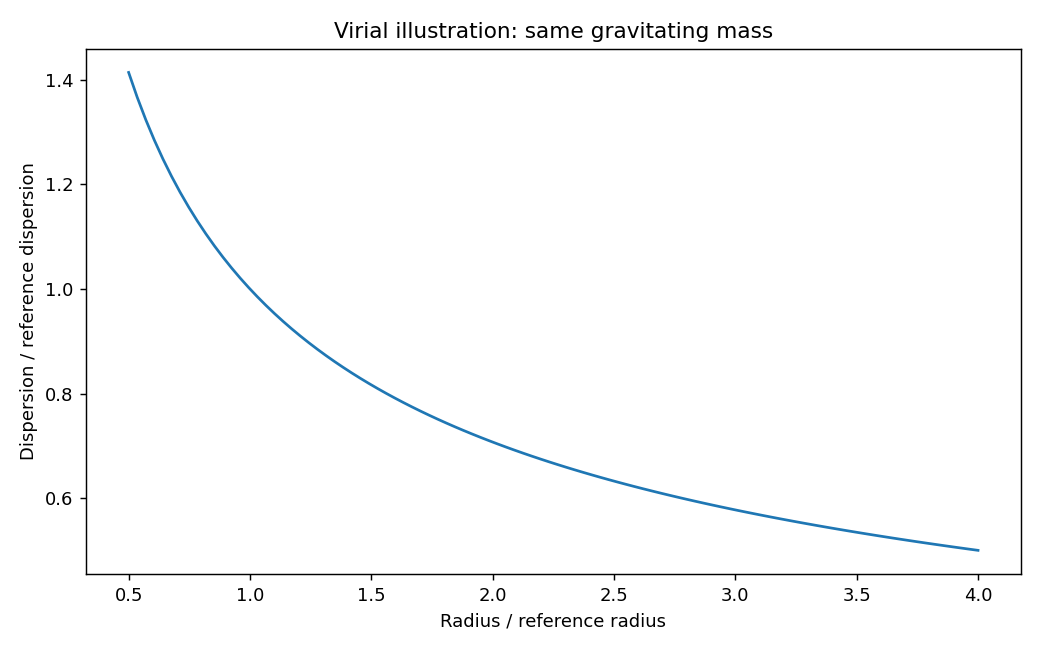

In [ ]:
# These are size ratios for an example, not catalogue measurements.
radius_ratio = np.linspace(0.5, 4, 100)
sigma_ratio = (1 / radius_ratio) ** 0.5

print('Dispersion ratio if the radius doubles:', (1 / 2) ** 0.5)
print('Speed ratio for the 4 kpc and 8 kpc example:', (8 / 4) ** 0.5)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(radius_ratio, sigma_ratio)
plt.xlabel('Radius / reference radius')
plt.ylabel('Dispersion / reference dispersion')
plt.title('Virial illustration: same gravitating mass')
plt.tight_layout()
plt.show()


**Before trying this with the actual catalogue:** both input schemas define `r_e` as an r-band major-axis effective radius in **arcseconds**. It is an angular light radius, not a radius in kpc or a measured half-mass radius. A physically large, distant galaxy can look small on the sky. Do not put `r_e` straight into a kpc calculation or interpret a raw `r_e`–dispersion trend as a physical-size result.

A proper observational follow-up would need justified physical radii, a stated distance conversion and control for stellar mass. None is introduced here. This is also why a size term appears in the lecture's Fundamental Plane discussion; we do not fit a Fundamental Plane in this notebook.

**Check to explain:** if mass and structure stay fixed but radius halves, what happens to dispersion? The prediction is a factor $\sqrt{2}$ increase, not a factor 2 increase.


## 2. Galaxy evolution: two simple merger examples

The merger slides compare mass, size and velocity dispersion. We can reproduce their limiting scalings with a few arrays.

Let $f=M_{\rm final}/M_{\rm initial}$ be an illustrative mass-growth factor. In the simplified equal-mass merger scaling,

$$R/R_0=f,\qquad \sigma/\sigma_0\simeq1.$$

In the idealised minor-merger limit shown in the slides,

$$R/R_0\simeq f^2,\qquad \sigma/\sigma_0\simeq f^{-1/2}.$$

The second result follows from substituting the radius scaling into the same virial ratio. These models use simplified energy arguments; the minor-merger limit assumes the accreted systems have much smaller velocity dispersions. They omit gas dissipation, orbital-energy complications and structural changes. The four mass factors below illustrate the scalings; they are not four observed mergers or a time sequence reconstructed from SAMI.

**Source:** `PHYS3116_2026T3_lecture_07_Tue4-1.pdf`, PDF pp. 28–36, especially pp. 34–35. Gas-rich, gas-poor, major and minor mergers are distinct classifications; these two curves do not describe every merger.


   mass_ratio  ...  minor_dispersion_ratio
0           1  ...                1.000000
1           2  ...                0.707107
2           3  ...                0.577350
3           4  ...                0.500000

[4 rows x 5 columns]


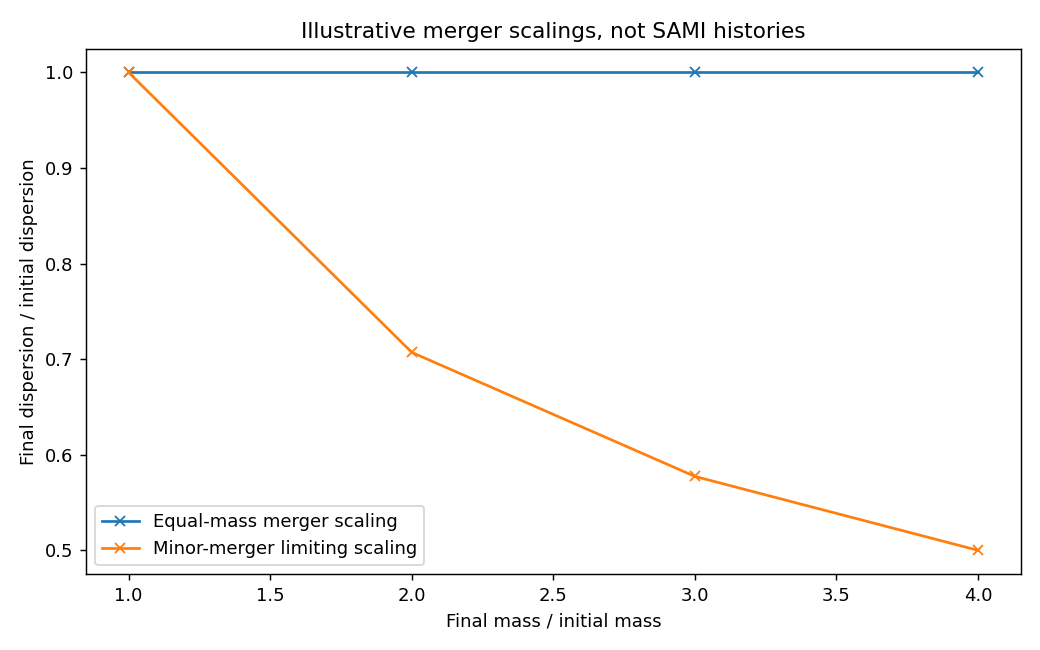

In [ ]:
growth = np.array([1, 2, 3, 4])

major_radius = growth
minor_radius = growth ** 2
major_sigma = (growth / major_radius) ** 0.5
minor_sigma = (growth / minor_radius) ** 0.5

mergers = pd.DataFrame({
    'mass_ratio': growth,
    'major_radius_ratio': major_radius,
    'minor_radius_ratio': minor_radius,
    'major_dispersion_ratio': major_sigma,
    'minor_dispersion_ratio': minor_sigma
})
print(mergers)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(growth, major_sigma, 'x-', label='Equal-mass merger scaling')
plt.plot(growth, minor_sigma, 'x-', label='Minor-merger limiting scaling')
plt.xlabel('Final mass / initial mass')
plt.ylabel('Final dispersion / initial dispersion')
plt.title('Illustrative merger scalings, not SAMI histories')
plt.legend()
plt.tight_layout()
plt.show()


For a mass factor of 2, the first model gives a radius factor of 2 and unchanged dispersion. The second limiting model gives a radius factor of 4 and a dispersion factor of about 0.707. Mass can grow without dispersion increasing in the same way.

This supplies a possible physical connection between assembly history and a mass–dispersion relation. It does **not** let us label individual galaxies as merger remnants from their position on our plot. Gas-rich evolution, rotation, structure and measurement aperture can also matter.

Quenching adds another distinction: a fading stellar population can change its light without being the same process as a rearrangement of stellar orbits. The lecture's SAMI discussion of disk fading and interactions is on PDF pp. 20–21 of `PHYS3116_2026T3_lecture_08_Fri4-1.pdf`. Our sample and fits do not independently test that evolutionary scenario.

**Check to explain:** why would an increase in stellar mass alone be insufficient to reconstruct a galaxy's merger history?


## 3. How assumptions about stellar mass could affect the fit

The mass-to-light relation is

$$M_\star=(M_\star/L)L.$$

The inferred mass-to-light ratio depends on the stellar population. The IMF, stellar ages, metallicities and modelling assumptions matter. As a simple population ages, its luminosity and colours evolve; its mass-to-light ratio can change. The supplied SAMI schemas do not specify all the assumptions behind each catalogue mass, so this notebook does not infer or correct their IMF.

Here is one **hypothetical sensitivity check**: what if all stellar masses were larger by a factor of 2? This factor is chosen to make the algebra easy to see. It is **not** a measured mass error, an uncertainty interval, or a conversion between named IMFs.

Because the code already uses logarithmic mass,

$$x'=\log_{10}(2M_\star)=x+\log_{10}2.$$

If $y=ax+b$, substituting $x=x'-\log_{10}2$ gives

$$y=ax'+\bigl(b-a\log_{10}2\bigr).$$

A uniform mass rescaling changes the intercept and leaves the slope unchanged. The next cell tests that using the actual sample. A correction that varies from galaxy to galaxy could affect the slope or scatter; a uniform shift cannot test that possibility.

**Sources:** `PHYS3116_2026T3_lecture_GalaxyML-2.pdf`, PDF pp. 2–7; `PHYS3116_2026T3_lecture_StellarPopulationModels_IMF.pdf`, PDF pp. 16 and 21–23. The rescaling calculation is algebra applied to those concepts, not a population-synthesis model.


Original slope: 0.3331111896493938
Shifted-mass slope: 0.33311118964939385
Original intercept: -1.3600227480340585
Shifted-mass intercept: -1.4602992080098405


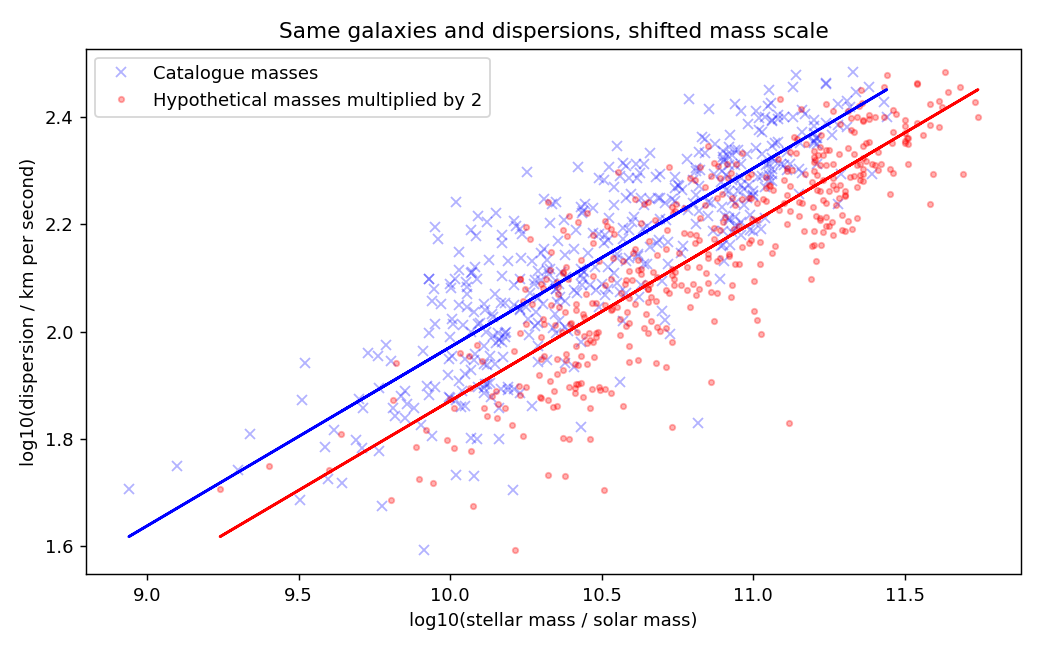

In [ ]:
factor = 2
shifted_mass = mass + np.log(factor) / np.log(10)
shifted_fit = stats.linregress(shifted_mass, sigma)
shifted_line = shifted_fit.slope * shifted_mass + shifted_fit.intercept

print('Original slope:', fit.slope)
print('Shifted-mass slope:', shifted_fit.slope)
print('Original intercept:', fit.intercept)
print('Shifted-mass intercept:', shifted_fit.intercept)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(mass, sigma, 'x', alpha=0.3, color='blue', label='Catalogue masses')
plt.plot(shifted_mass, sigma, '.', alpha=0.3, color='red', label='Hypothetical masses multiplied by 2')
plt.plot(mass, line, color='blue')
plt.plot(shifted_mass, shifted_line, color='red')
plt.xlabel('log10(stellar mass / solar mass)')
plt.ylabel('log10(dispersion / km per second)')
plt.title('Same galaxies and dispersions, shifted mass scale')
plt.legend()
plt.tight_layout()
plt.show()


The shift is about 0.301 dex. For the supplied sample, the slope stays about 0.333, while the intercept moves from about −1.360 to −1.460. The original `mass` array and catalogue CSV have not been changed. A tiny numerical difference between the printed slopes is floating-point rounding.

**Checks for a literature comparison:** are the mass definitions and population assumptions comparable? Are the same aperture, galaxy selection and fitting direction used? The Oh et al. equation reproduced on lecture 5 PDF p. 30 uses a reference category marked $B/T>0.8$; our E/E-S0 morphology cut does not recreate that selection. If both studies' mass scales were recalibrated, both relations would need consistent treatment. Do not attribute the observed slope difference to a uniform mass offset: this calculation shows why that alone cannot change the slope.
